**Chapter 8's Execises: Exponential Smoothing**

In [1]:
library(fpp3)

Warning message:
"package 'fpp3' was built under R version 4.5.3"
── Attaching packages ──────────────────────────────────────────── fpp3 1.0.3 ──

✔ tibble      3.3.0     ✔ tsibble     1.2.0
✔ dplyr       1.1.4     ✔ tsibbledata 0.4.1
✔ tidyr       1.3.1     ✔ ggtime      1.0.0
✔ lubridate   1.9.4     ✔ feasts      0.5.0
✔ ggplot2     4.0.0     ✔ fable       0.5.0

Warning message:
"package 'tsibble' was built under R version 4.5.3"
Warning message:
"package 'tsibbledata' was built under R version 4.5.3"
Warning message:
"package 'ggtime' was built under R version 4.5.3"
Warning message:
"package 'feasts' was built under R version 4.5.3"
Warning message:
"package 'fabletools' was built under R version 4.5.3"
Warning message:
"package 'fable' was built under R version 4.5.3"
── Conflicts ───────────────────────────────────────────────── fpp3_conflicts ──
✖ lubridate::date()    masks base::date()
✖ dplyr::filter()      masks stats::filter()
✖ tsibble::intersect() masks base::intersect()

**8.1 Consider the number of pigs slaughtered in Victoria, available in the aus_livestock dataset.**

In [3]:
head(aus_livestock)
pigs <- aus_livestock |>
  filter(State == "Victoria", Animal == "Pigs") |>
  filter(!is.na(Count))

head(pigs)

Month,Animal,State,Count
<mth>,<fct>,<fct>,<dbl>
1976 7月,"Bulls, bullocks and steers",Australian Capital Territory,2300
1976 8月,"Bulls, bullocks and steers",Australian Capital Territory,2100
1976 9月,"Bulls, bullocks and steers",Australian Capital Territory,2100
1976 10月,"Bulls, bullocks and steers",Australian Capital Territory,1900
1976 11月,"Bulls, bullocks and steers",Australian Capital Territory,2100
1976 12月,"Bulls, bullocks and steers",Australian Capital Territory,1800


Month,Animal,State,Count
<mth>,<fct>,<fct>,<dbl>
1972 7月,Pigs,Victoria,94200
1972 8月,Pigs,Victoria,105700
1972 9月,Pigs,Victoria,96500
1972 10月,Pigs,Victoria,117100
1972 11月,Pigs,Victoria,104600
1972 12月,Pigs,Victoria,100500


In [4]:
# a. SES
fit_ses <- pigs |>
  model(ESS = ETS(Count ~ error("A") + trend("N") + season("N")))

fit_ses |> tidy()

fc_ses <- fit_ses |> forecast(h = 4)
fc_ses

Animal,State,.model,term,estimate
<fct>,<fct>,<chr>,<chr>,<dbl>
Pigs,Victoria,ESS,alpha,3.221247e-01
Pigs,Victoria,ESS,l[0],1.006466e+05


Animal,State,.model,Month,Count,.mean
<fct>,<fct>,<chr>,<mth>,<dist>,<dbl>
Pigs,Victoria,ESS,2019 1月,"N(95187, 8.7e+07)",95186.56
Pigs,Victoria,ESS,2019 2月,"N(95187, 9.7e+07)",95186.56
Pigs,Victoria,ESS,2019 3月,"N(95187, 1.1e+08)",95186.56
Pigs,Victoria,ESS,2019 4月,"N(95187, 1.1e+08)",95186.56


In [5]:
# b. 95% prediction interval for the first forecast using y^±1.96s
#  where ss is the standard deviation of the residuals
y_hat <- fc_ses |> pull(.mean) |> head(1)

s <- fit_ses |> augment() |> pull(.resid) |> sd(na.rm = TRUE)

manual_lower <- y_hat - 1.96 * s
manual_upper <- y_hat + 1.96 * s
cat("manual lower bound: ", manual_lower, "\n")
cat("manual upper bound: ", manual_upper)

r_interval <- fc_ses |> hilo(level = 95) |> head(1)
r_interval

manual lower bound:  76871.01 
manual upper bound:  113502.1

Animal,State,.model,Month,Count,.mean,95%
<fct>,<fct>,<chr>,<mth>,<dist>,<dbl>,<hilo>
Pigs,Victoria,ESS,2019 1月,"N(95187, 8.7e+07)",95186.56,"[76854.79, 113518.3]95"


5.2 Write your own function to implement simple exponential smoothing. The function should take arguments y (the time series), alpha (the smoothing parameter αα) and level (the initial level ℓ0ℓ0​). It should return the forecast of the next observation in the series. Does it give the same forecast as ETS()?

In [6]:
my_ses <- function(y, alpha, level) {
  l <- level

  for (i in 1 : length(y)) {
    l <- alpha * y[i] + (1 - alpha) * l
  }
  return(l)
}

params <- fit_ses |> tidy()
ets_forecast <- fit_ses |> forecast(h = 1) |> pull(.mean)

my_forecast <- my_ses(
  y = pigs |> pull(Count),
  alpha = params |> filter(term == "alpha") |> pull(estimate),
  level = params |> filter(term == "l[0]") |> pull(estimate)
)

cat("ETS forecast:", ets_forecast, " | self_implemented:", my_forecast, "\n")

ETS forecast: 95186.56  | self_implemented: 95186.56 


5.3 Modify your function from the previous exercise to return the sum of squared errors rather than the forecast of the next observation. Then use the optim() function to find the optimal values of αα and ℓ0ℓ0​. Do you get the same values as the ETS() function?

In [7]:
head(params)

my_ses_sse <- function(par, y) {
  alpha <- par[1]
  l <- par[2]

  sse <- 0
  for (i in 1:length(y)) {
    error <- y[i] - l
    sse <- sse + error^2

    l <- alpha * y[i] + (1 - alpha) * l
  }
  return(sse)
}

y_values <- pigs |> pull(Count)

opt_result <- optim(
  par = c(alpha = 0.5, l0 = y_values[1]),
  fn = my_ses_sse,
  y = y_values,
  method = "L-BFGS-B",
  lower = c(0.0001, -Inf),
  upper = c(0.9999, Inf)
)

opt_alpha <- opt_result$par[1]
opt_l0 <- opt_result$par[2]

cat("optim() found optimal alpha: ", opt_alpha, "\n")
cat("optim() found optimal l0: ", opt_l0)

Animal,State,.model,term,estimate
<fct>,<fct>,<chr>,<chr>,<dbl>
Pigs,Victoria,ESS,alpha,3.221247e-01
Pigs,Victoria,ESS,l[0],1.006466e+05


optim() found optimal alpha:  0.3219966 
optim() found optimal l0:  100532.9

5.4 Combine your previous two functions to produce a function that both finds the optimal values of αα and ℓ0ℓ0​, and produces a forecast of the next observation in the series.

In [12]:
my_ses_auto_forecast <- function(y) {
  calc_sse <- function(par) {
    alpha <- par[1]
    l <- par[2]
    sse <- 0
    for (i in 1:length(y)) {
      error <- y[i] - l
      sse <- sse + error^2
      l <- alpha * y[i] + (1 - alpha) * l
    }
    return(sse)
  }

  opt_result <- optim(
    par = c(0.5, y[1]),
    fn = calc_sse,
    method = "L-BFGS-B",
    lower = c(0.0001, -Inf),
    upper = c(0.9999, Inf)
  )

  best_alpha <- opt_result$par[1]
  best_l0 <- opt_result$par[2]

  l <- best_l0
  for (i in 1:length(y)) {
    l <- best_alpha * y[i] + (1 - best_alpha) * l
  }

  return(list(
    forecast = l,
    alpha = best_alpha,
    l0 = best_l0
  ))
}

In [13]:
my_result <- my_ses_auto_forecast(y_values)
my_result

$forecast
[1] 95186.74

$alpha
[1] 0.3219966

$l0
[1] 100532.9

5.5 Select one country from `global_economy` to analyse its exports.

In [18]:
dnk_exports <- global_economy |>
  filter(Country == "Denmark") |>
  filter(!is.na(Exports))

head(aus_exports)

Country,Code,Year,GDP,Growth,CPI,Imports,Exports,Population
<fct>,<fct>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Denmark,DNK,1960,6248946880,NA,8.245702,34.32181,32.31046,4579603
Denmark,DNK,1961,6933842099,6.3788325,8.530313,32.34234,29.99696,4611687
Denmark,DNK,1962,7812968114,5.6668222,9.159664,32.50493,28.61946,4647727
Denmark,DNK,1963,8316692386,0.6370212,9.718865,30.79128,30.40296,4684483
Denmark,DNK,1964,9506678763,9.2699382,10.019448,32.62801,29.85216,4722072
Denmark,DNK,1965,10678897387,4.5552548,10.565508,31.54015,29.29713,4759012


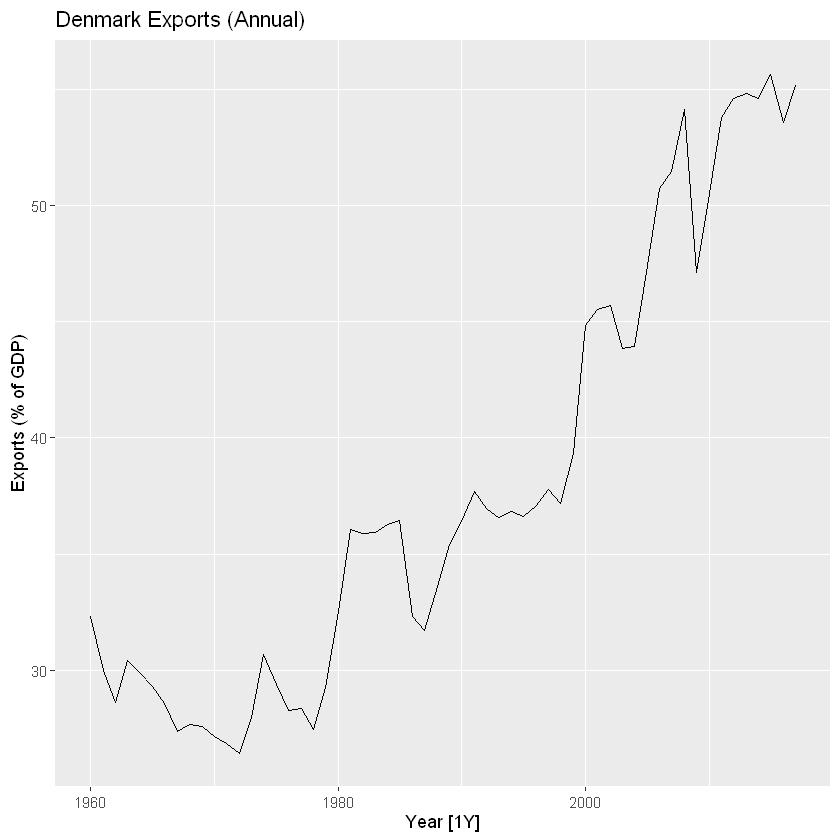

In [19]:
# a. plot
dnk_exports |>
  autoplot(Exports) +
  labs(title = "Denmark Exports (Annual)", y = "Exports (% of GDP)")

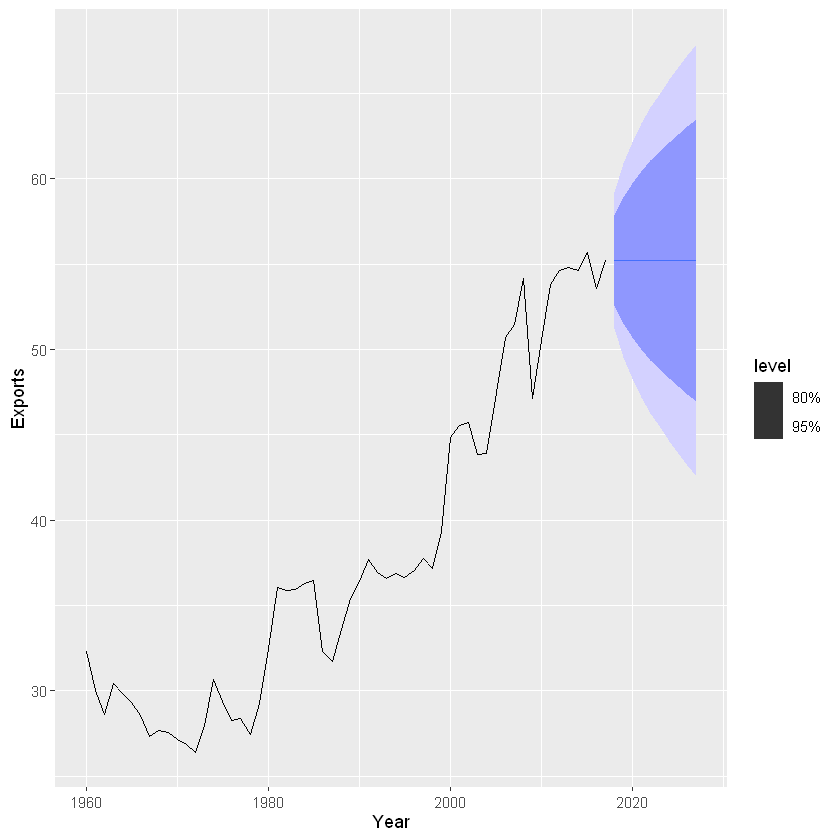

In [ ]:
# b. Use an ETS(A,N,N) model to forecast the series, and plot the forecasts.
fit_ann <- aus_exports |>
  model(SES = ETS(Exports ~ error("A") + trend("N") + season("N")))

fit_ann |> forecast(h = 10) |> autoplot(aus_exports)

In [23]:
# c. Compute the RMSE values for the training data.
acc_ann <- fit_ann |> accuracy()
rmse_ann <- acc_ann |> pull(RMSE)
cat("ETS(A,N,N)'s RMSE: ", rmse_ann, "\n")

ETS(A,N,N)'s RMSE:  2.007573 


In [25]:
# e. Compare the results to those from an ETS(A,A,N) model.
# (Remember that the trended model is using one more parameter than the simpler model.)
# Discuss the merits of the two forecasting methods for this data set.
fit_aan <- aus_exports |>
  model(Holt = ETS(Exports ~ error("A") + trend("A") + season("N")))

acc_aan <- fit_aan |> accuracy()
rmse_aan <- acc_aan |> pull(RMSE)

fit_ann |> report()
fit_aan |> report()

Series: Exports 
Model: ETS(A,N,N) 
  Smoothing parameters:
    alpha = 0.9998996 

  Initial states:
     l[0]
 32.31581

  sigma^2:  4.1743

     AIC     AICc      BIC 
322.3492 322.7936 328.5305 
Series: Exports 
Model: ETS(A,A,N) 
  Smoothing parameters:
    alpha = 0.9998998 
    beta  = 0.0001000284 

  Initial states:
     l[0]      b[0]
 32.46829 0.4192062

  sigma^2:  4.1654

     AIC     AICc      BIC 
324.1161 325.2699 334.4183 


In [27]:
# f. Calculate a 95% prediction interval for the first forecast for each model,
# using the RMSE values and assuming normal errors.
# Compare your intervals with those produced using R.
# Prepare data (in case it's not in your current environment)
aus_exports <- global_economy |>
  filter(Country == "Australia") |>
  filter(!is.na(Exports))

# ==========================================
# Refit models and generate forecasts (ensure variables exist)
# ==========================================
fit_ann <- aus_exports |>
  model(SES = ETS(Exports ~ error("A") + trend("N") + season("N")))
fc_ann <- fit_ann |> forecast(h = 10)

fit_aan <- aus_exports |>
  model(Holt = ETS(Exports ~ error("A") + trend("A") + season("N")))
fc_aan <- fit_aan |> forecast(h = 10)

# Extract RMSE values
rmse_ann <- fit_ann |> accuracy() |> pull(RMSE)
rmse_aan <- fit_aan |> accuracy() |> pull(RMSE)


# ==========================================
# f. Manually calculate the 95% prediction interval
# ==========================================

# --- For ETS(A,N,N) model ---
# 1. Extract the first forecast value
y_hat_ann <- fc_ann |> pull(.mean) |> head(1)

# 2. Manually calculate the 95% prediction interval
lower_ann <- y_hat_ann - 1.96 * rmse_ann
upper_ann <- y_hat_ann + 1.96 * rmse_ann
cat("Manual SES interval: [", lower_ann, ",", upper_ann, "]\n")

# 3. Extract the R-generated interval for comparison
fc_ann |> hilo(level = 95) |> head(1)


# --- For ETS(A,A,N) model ---
# 1. Extract the first forecast value
y_hat_aan <- fc_aan |> pull(.mean) |> head(1)

# 2. Manually calculate the 95% prediction interval
lower_aan <- y_hat_aan - 1.96 * rmse_aan
upper_aan <- y_hat_aan + 1.96 * rmse_aan
cat("Manual Holt interval: [", lower_aan, ",", upper_aan, "]\n")

# 3. Extract the R-generated interval for comparison
fc_aan |> hilo(level = 95) |> head(1)

Manual SES interval: [ 18.35944 , 22.85488 ]


Country,.model,Year,Exports,.mean,95%
<fct>,<chr>,<dbl>,<dist>,<dbl>,<hilo>
Australia,SES,2018,"N(21, 1.4)",20.60716,"[18.3197, 22.89462]95"


Manual Holt interval: [ 18.64986 , 23.02743 ]


Country,.model,Year,Exports,.mean,95%
<fct>,<chr>,<dbl>,<dist>,<dbl>,<hilo>
Australia,Holt,2018,"N(21, 1.3)",20.83864,"[18.57028, 23.107]95"


6. Forecast the Chinese GDP from the global_economy data set using an ETS model. Experiment with the various options in the ETS() function to see how much the forecasts change with damped trend, or with a Box-Cox transformation. Try to develop an intuition of what each is doing to the forecasts.

Warning message:
"1 error encountered for BoxCox_Log
[1] Exogenous regressors are not supported for this model type.
"
Warning message:
"Removed 15 rows containing missing values or values outside the scale range
(`geom_line()`)."


.model,AICc
<chr>,<dbl>
Auto_ETS,3103.218
Linear_Trend,3259.207
Damped_Trend,3261.834


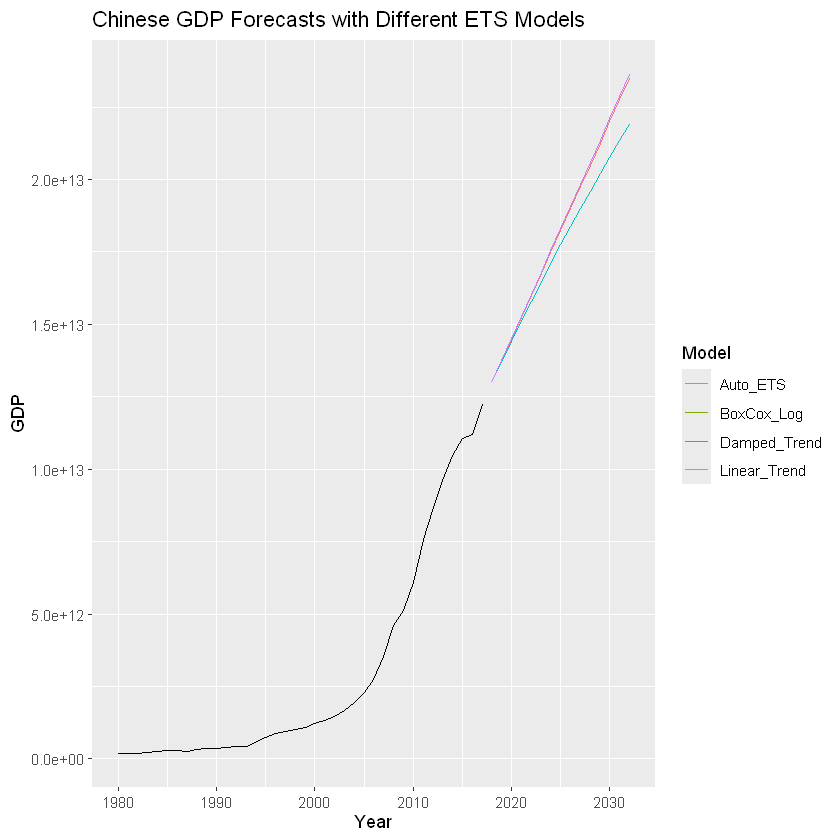

In [28]:
# 1. Extract Chinese GDP data
china_gdp <- global_economy |>
  filter(Country == "China") |>
  filter(!is.na(GDP))

# 2. Fit different ETS models
fit_models <- china_gdp |>
  model(
    # Baseline: Linear trend without damping
    Linear_Trend = ETS(GDP ~ error("A") + trend("A") + season("N")),

    # Damped trend: Growth slows down over time
    Damped_Trend = ETS(GDP ~ error("A") + trend("Ad") + season("N")),

    # Box-Cox transformation (lambda = 0, equivalent to log transform)
    # Log transform stabilizes exponential growth and variance
    BoxCox_Log = ETS(GDP ~ error("A") + trend("A") + season("N") + box_cox(0)),

    # Automatic selection (usually picks multiplicative or damped models for GDP)
    Auto_ETS = ETS(GDP)
  )

# 3. Generate forecasts for the next 15 years
fc <- fit_models |> forecast(h = 15)

# 4. Plot the forecasts
fc |>
  autoplot(china_gdp |> filter(Year >= 1980), level = NULL) +
  labs(
    title = "Chinese GDP Forecasts with Different ETS Models",
    y = "GDP",
    x = "Year"
  ) +
  guides(colour = guide_legend(title = "Model"))

# 5. Optional: Compare AICc to see which model fits best statistically
fit_models |> glance() |> arrange(AICc) |> select(.model, AICc)

7. Find an ETS model for the Gas data from aus_production and forecast the next few years. Why is multiplicative seasonality necessary here? Experiment with making the trend damped. Does it improve the forecasts?

.model,AICc
<chr>,<dbl>
Multiplicative,1681.794
Auto_ETS,1681.794
Multiplicative_Damped,1685.091
Additive,1873.318


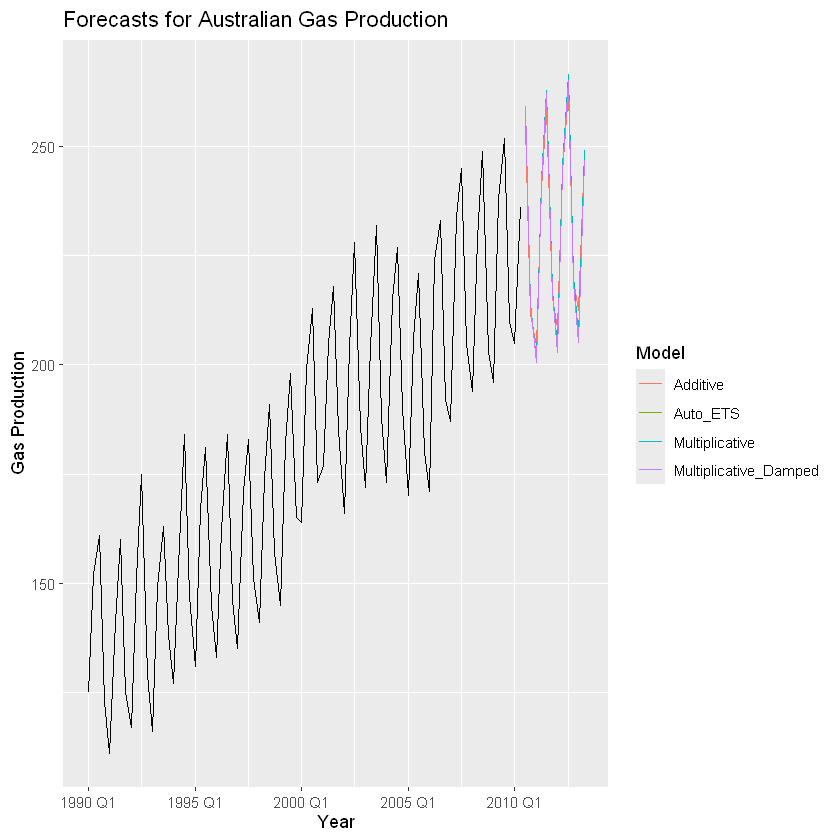

In [29]:
# 1. Extract Gas data and remove missing values
gas_data <- aus_production |>
  filter(!is.na(Gas))

# 2. Fit different ETS models for comparison
fit_gas <- gas_data |>
  model(
    # Additive seasonality (for comparison)
    Additive = ETS(Gas ~ error("A") + trend("A") + season("A")),

    # Multiplicative seasonality (The likely best manual fit)
    Multiplicative = ETS(Gas ~ error("M") + trend("A") + season("M")),

    # Multiplicative with Damped Trend
    Multiplicative_Damped = ETS(Gas ~ error("M") + trend("Ad") + season("M")),

    # Automatic Selection
    Auto_ETS = ETS(Gas)
  )

# 3. Generate forecasts for the next 12 quarters (3 years)
fc_gas <- fit_gas |> forecast(h = 12)

# 4. Plot the forecasts
fc_gas |>
  autoplot(gas_data |> filter(year(Quarter) >= 1990), level = NULL) +
  labs(
    title = "Forecasts for Australian Gas Production",
    y = "Gas Production",
    x = "Year"
  ) +
  guides(colour = guide_legend(title = "Model"))

# 5. Check AICc to see which model is statistically the best
fit_gas |> glance() |> arrange(AICc) |> select(.model, AICc)

8 .Recall your retail time series data (from Exercise 7 in Section 2.10).

    b. Apply Holt-Winters’ multiplicative method to the data. Experiment with making the trend damped.
    c. Compare the RMSE of the one-step forecasts from the two methods. Which do you prefer?
    d. Check that the residuals from the best method look like white noise.
    e. Now find the test set RMSE, while training the model to the end of 2010. Can you beat the seasonal naïve approach from Exercise 7 in Section 5.11?


# A tibble: 2 × 3
  .model                 RMSE   MAE
  <chr>                 <dbl> <dbl>
1 Multiplicative        0.613 0.450
2 Damped_Multiplicative 0.616 0.444


State,Industry,.model,lb_stat,lb_pvalue
<chr>,<chr>,<chr>,<dbl>,<dbl>
Northern Territory,"Clothing, footwear and personal accessory retailing",Best_ETS,23.81679,0.472113


# A tibble: 2 × 3
  .model    RMSE   MAE
  <chr>    <dbl> <dbl>
1 Best_ETS  1.15 0.878
2 SNaive    1.55 1.24 


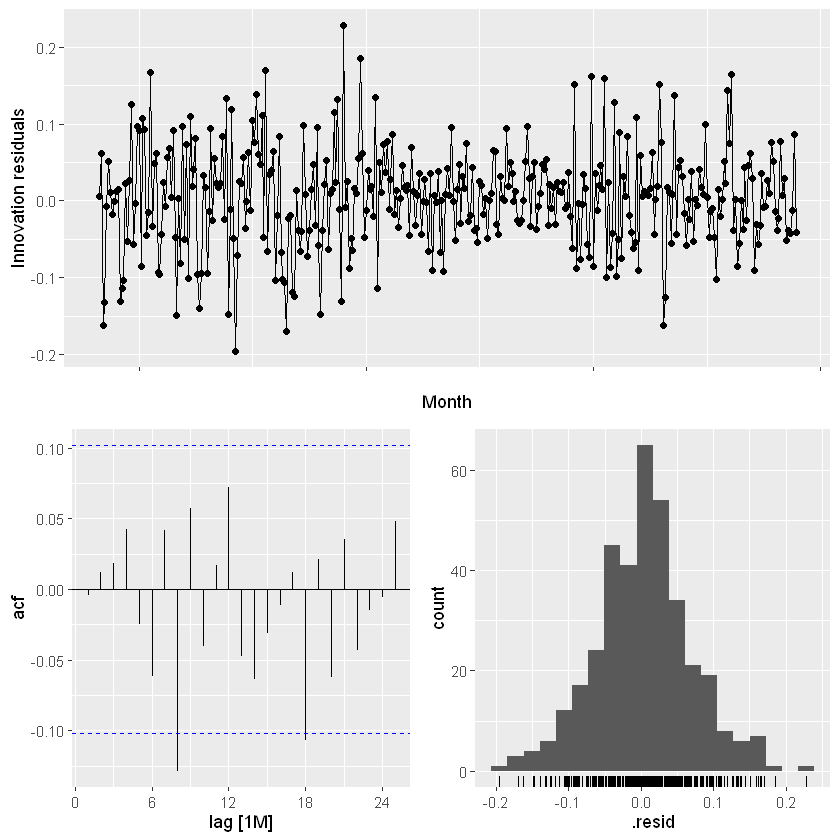

In [31]:

set.seed(12345678)
myseries <- aus_retail |>
  filter(`Series ID` == sample(aus_retail$`Series ID`, 1))
# ==========================================
# b. Apply Holt-Winters' multiplicative method (with and without damping)
# ==========================================
fit_models <- myseries |>
  model(
    Multiplicative = ETS(Turnover ~ error("M") + trend("A") + season("M")),
    Damped_Multiplicative = ETS(Turnover ~ error("M") + trend("Ad") + season("M"))
  )

# ==========================================
# c. Compare the RMSE of the one-step forecasts
# ==========================================
# The accuracy() function provides in-sample (training) errors, which are essentially 1-step ahead errors.
acc_train <- fit_models |> accuracy()
print(acc_train |> select(.model, RMSE, MAE))

# ==========================================
# d. Check residuals of the best method
# ==========================================
# Assuming Damped_Multiplicative is the best (usually the case for long-term retail)
best_fit <- myseries |>
  model(Best_ETS = ETS(Turnover ~ error("M") + trend("Ad") + season("M")))

# Plot residuals
best_fit |> gg_tsresiduals()

# Ljung-Box test for white noise
best_fit |> 
  augment() |> 
  features(.innov, ljung_box, lag = 24)

# ==========================================
# e. Test set RMSE (Train up to 2010) vs SNAIVE
# ==========================================
# 1. Split data
train_data <- myseries |> filter(year(Month) < 2011)
test_data <- myseries |> filter(year(Month) >= 2011)

# 2. Fit ETS and SNAIVE on training data
fit_compare <- train_data |>
  model(
    Best_ETS = ETS(Turnover ~ error("M") + trend("Ad") + season("M")),
    SNaive = SNAIVE(Turnover)
  )

# 3. Forecast the test period
fc_compare <- fit_compare |> forecast(new_data = test_data)

# 4. Calculate test set RMSE
test_acc <- fc_compare |> accuracy(test_data)
print(test_acc |> select(.model, RMSE, MAE))

9. For the same retail data, try an STL decomposition applied to the Box-Cox transformed series, followed by ETS on the seasonally adjusted data. How does that compare with your best previous forecasts on the test set?

# A tibble: 2 × 3
  .model             RMSE   MAE
  <chr>             <dbl> <dbl>
1 Best_Previous_ETS  1.15 0.878
2 STL_BoxCox_ETS     1.06 0.820


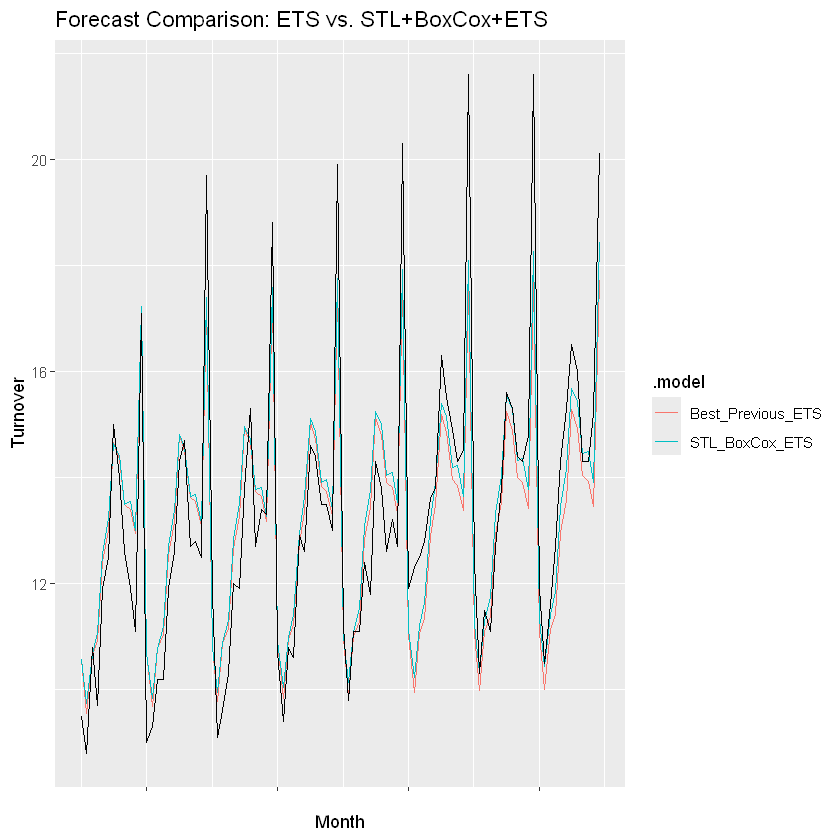

In [ ]:
# 1. Split the data into training and test sets
train_data <- myseries |> filter(year(Month) < 2011)
test_data <- myseries |> filter(year(Month) >= 2011)

# 2. Fit both models on the training data
fit_compare <- train_data |>
  model(
    # Previous Best Model: Damped Multiplicative ETS
    Best_Previous_ETS = ETS(Turnover ~ error("M") + trend("Ad") + season("M")),

    # New Approach: STL on Box-Cox transformed data + ETS on season_adjust
    STL_BoxCox_ETS = decomposition_model(
      # Apply Box-Cox (lambda = 0 means Log transform) before STL
      STL(box_cox(Turnover, 0) ~ season(window = "periodic")), 
      # Since data is log-transformed, an Additive ETS is used for the trend
      ETS(season_adjust ~ error("A") + trend("Ad") + season("N"))
    )
  )

# 3. Forecast the test period
fc_compare <- fit_compare |> forecast(new_data = test_data)

# 4. Calculate Test Set RMSE
test_acc <- fc_compare |> accuracy(test_data)
print(test_acc |> select(.model, RMSE, MAE))

# 5. Plot the forecasts against the actual data
fc_compare |>
  autoplot(test_data, level = NULL) +
  labs(title = "Forecast Comparison: ETS vs. STL+BoxCox+ETS")

10. Compute the total domestic overnight trips across Australia from the tourism dataset.<br>
a. Plot the data and describe the main features of the series.<br>
b. Decompose the series using STL and obtain the seasonally adjusted data.<br>
c. Forecast the next two years of the series using an additive damped trend method applied to the seasonally adjusted data. (This can be specified using decomposition_model().)<br>
d.Forecast the next two years of the series using an appropriate model for Holt’s linear method applied to the seasonally adjusted data (as before but without damped trend).<br>
e. Now use ETS() to choose a seasonal model for the data.<br>
f.Compare the RMSE of the ETS model with the RMSE of the models you obtained using STL decompositions. Which gives the better in-sample fits?<br>
g. Compare the forecasts from the three approaches? Which seems most reasonable?<br>
h. Check the residuals of your preferred model.

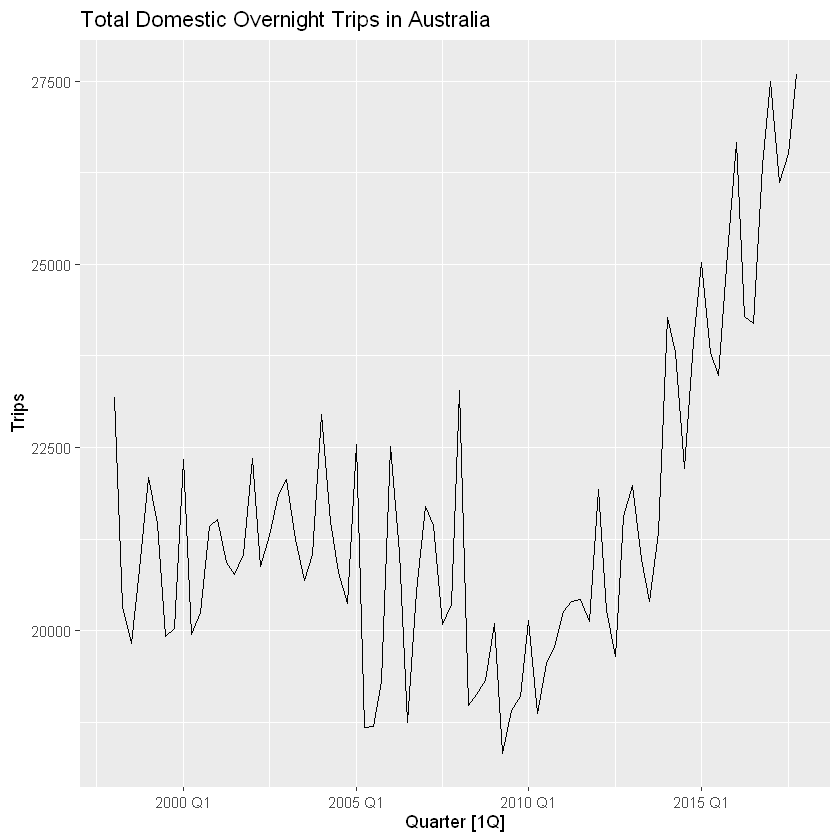

In [33]:
aus_trips <- tourism |>
  summarise(Trips = sum(Trips))

aus_trips |>
  autoplot(Trips) +
  labs(title = "Total Domestic Overnight Trips in Australia", y = "Trips")

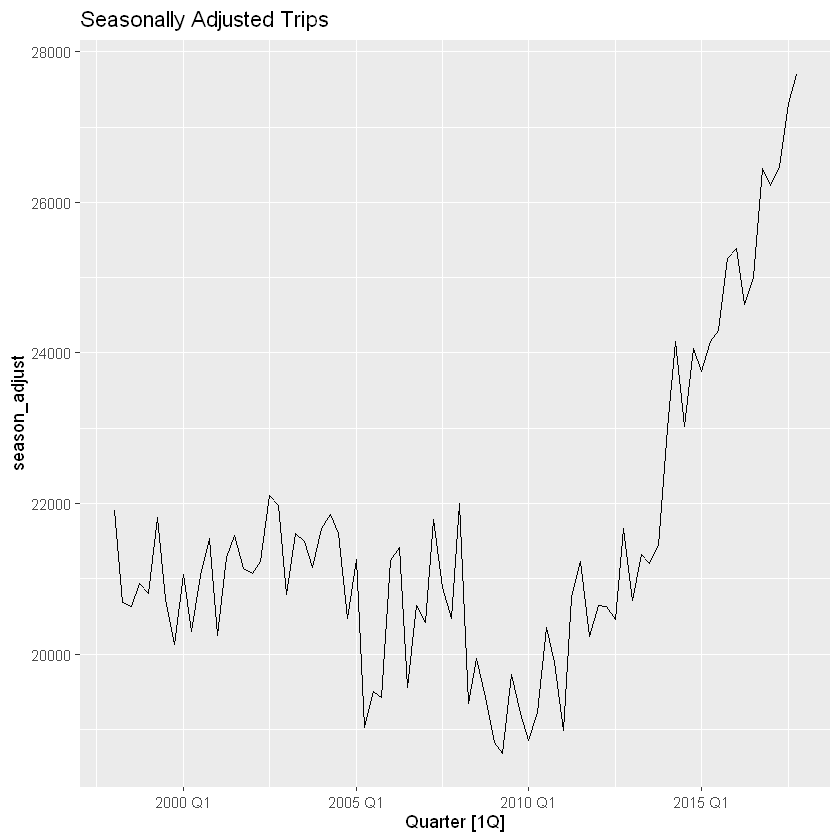

In [34]:
# STL decomposition with fixed seasonal window
stl_fit <- aus_trips |>
  model(STL(Trips ~ season(window = "periodic")))

# Extract the seasonally adjusted data
components(stl_fit) |>
  as_tsibble() |>
  autoplot(season_adjust) +
  labs(title = "Seasonally Adjusted Trips")

In [42]:
fit_decomp <- aus_trips |>
  model(
    # Damped trend applied to seasonally adjusted data
    Damped_STL = decomposition_model(
      STL(Trips ~ season(window = "periodic")),
      ETS(season_adjust ~ error("A") + trend("Ad") + season("N"))
    ),
    # Undamped (Holt's linear) applied to seasonally adjusted data
    Holt_STL = decomposition_model(
      STL(Trips ~ season(window = "periodic")),
      ETS(season_adjust ~ error("A") + trend("A") + season("N"))
    ),
    # Full ETS model (Auto-selection for the entire series)
    Full_ETS = ETS(Trips)
  )

# Compare accuracy metrics
fit_decomp |> accuracy() |> select(.model, RMSE, MAE)

.model,RMSE,MAE
<chr>,<dbl>,<dbl>
Damped_STL,801.0344,614.7766
Holt_STL,800.6906,611.3567
Full_ETS,793.6695,604.1089


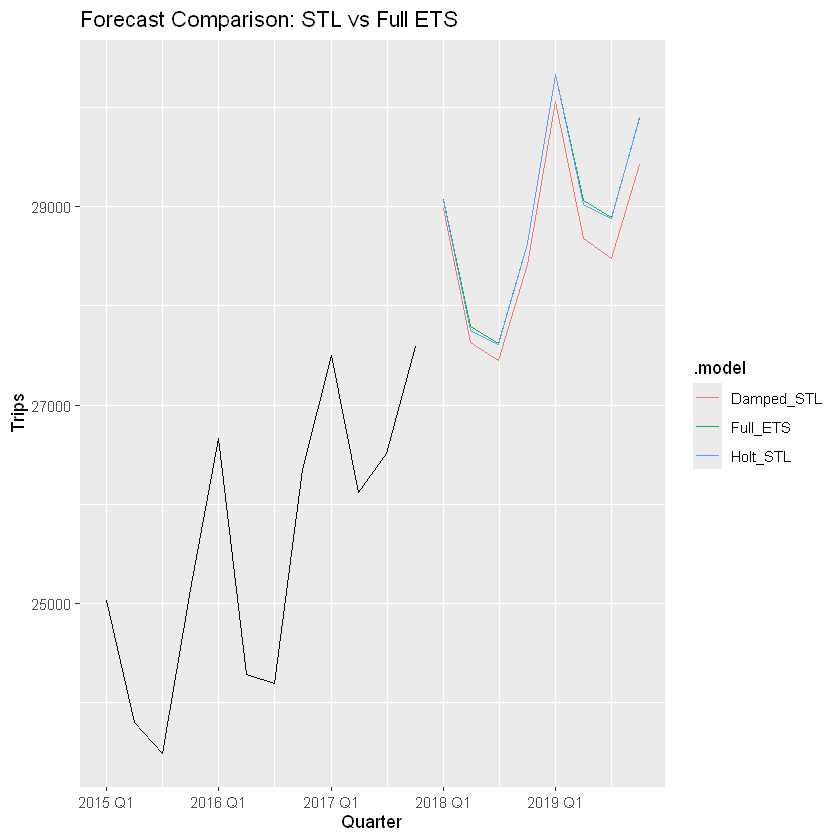

In [43]:
# Forecast the next 2 years (8 quarters)
fc <- fit_decomp |> forecast(h = 8)

# Plot the forecasts
fc |>
  autoplot(aus_trips |> filter(year(Quarter) >= 2015), level = NULL) +
  labs(title = "Forecast Comparison: STL vs Full ETS", y = "Trips")

.model,lb_stat,lb_pvalue
<chr>,<dbl>,<dbl>
Full_ETS,9.304563,0.6767201


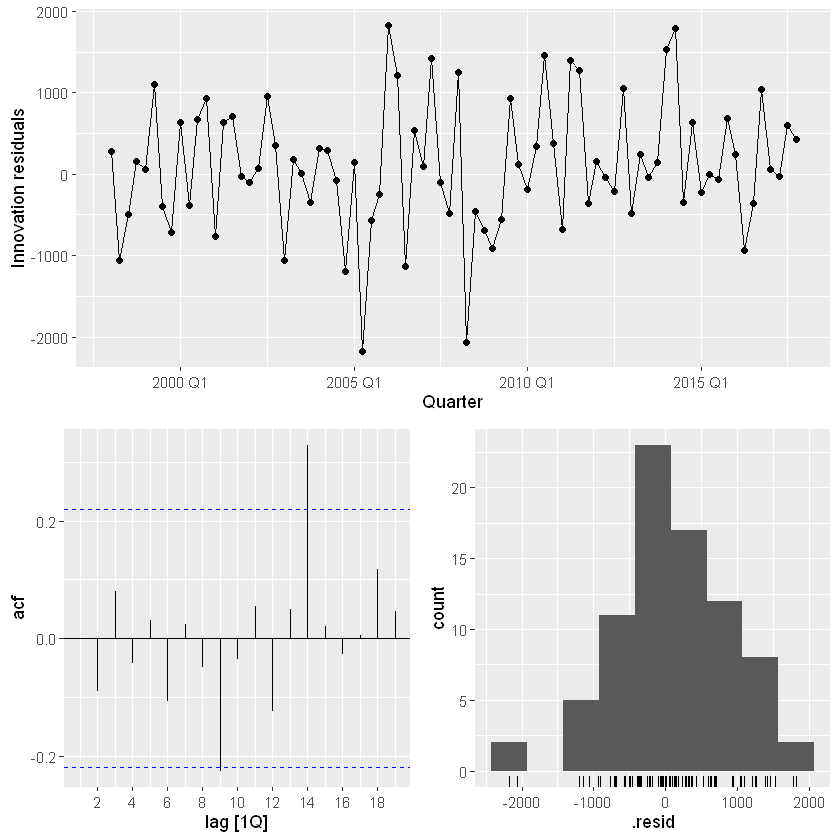

In [ ]:
# Extract residuals for the Full ETS model
fit_decomp |>
  select(Full_ETS) |>
  gg_tsresiduals()

# Ljung-Box test
fit_decomp |>
  select(Full_ETS) |>
  augment() |>
  features(.innov, ljung_box, lag = 12)

11. For this exercise use the quarterly number of arrivals to Australia from New Zealand, 1981 Q1 – 2012 Q3, from data set aus_arrivals.<br>

    a. Make a time plot of your data and describe the main features of the series.<br>
    b. Create a training set that withholds the last two years of available data. Forecast the test <br>set using an appropriate model for Holt-Winters’ multiplicative method.
    d. Why is multiplicative seasonality necessary here?<br>
    e. Forecast the two-year test set using each of the following methods:<br>
        an ETS model;<br>
        an additive ETS model applied to a log transformed series;<br>
        a seasonal naïve method;<br>
        an STL decomposition applied to the log transformed data followed by an ETS model applied to the seasonally adjusted (transformed) data.<br>


In [45]:
aus_nz <- aus_arrivals |>
  filter(Origin == "NZ", year(Quarter) >= 1981, year(Quarter) <= 2012) |>
  filter(quarter(Quarter) <= 3 | year(Quarter) < 2012)

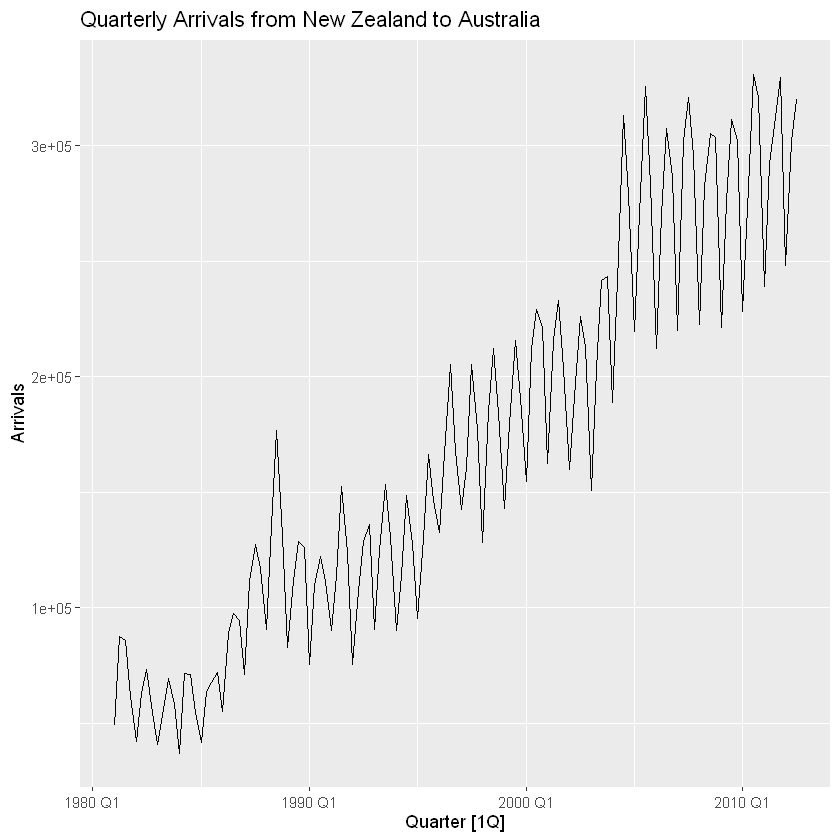

In [46]:
aus_nz |>
  autoplot(Arrivals) +
  labs(title = "Quarterly Arrivals from New Zealand to Australia", y = "Arrivals")

In [ ]:
train_data <- aus_nz |>
  filter(Quarter <= yearquarter("2010 Q3"))

test_data <- aus_nz |>
  anti_join(train_data, by = "Quarter")

fit_hw <- train_data |>
  model(HW_Multiplicative = ETS(Arrivals ~ error("M") + trend("A") + season("M")))

train_data |> has_gaps()

Origin,.gaps
<chr>,<lgl>
NZ,FALSE


In [50]:
fit_models <- train_data |>
  model(
    Auto_ETS = ETS(Arrivals),

    Log_Additive_ETS = ETS(log(Arrivals) ~ error("A") + trend("A") + season("A")),
    
    SNaive = SNAIVE(Arrivals),
    
    STL_Log_ETS = decomposition_model(
      STL(log(Arrivals) ~ season(window = "periodic")),
      ETS(season_adjust ~ error("A") + trend("A") + season("N"))
    )
  )

fc_models <- fit_models |> forecast(new_data = test_data)

In [52]:
fc_models |> accuracy(test_data) |>
  select(.model, RMSE, MAE) |>
  arrange(RMSE)

.model,RMSE,MAE
<chr>,<dbl>,<dbl>
Auto_ETS,14912.74,11420.69
Log_Additive_ETS,17764.71,12851.21
SNaive,18051.08,17156.25
STL_Log_ETS,27177.28,24096.16


.model,lb_stat,lb_pvalue
<chr>,<dbl>,<dbl>
Auto_ETS,25.52812,0.3775335


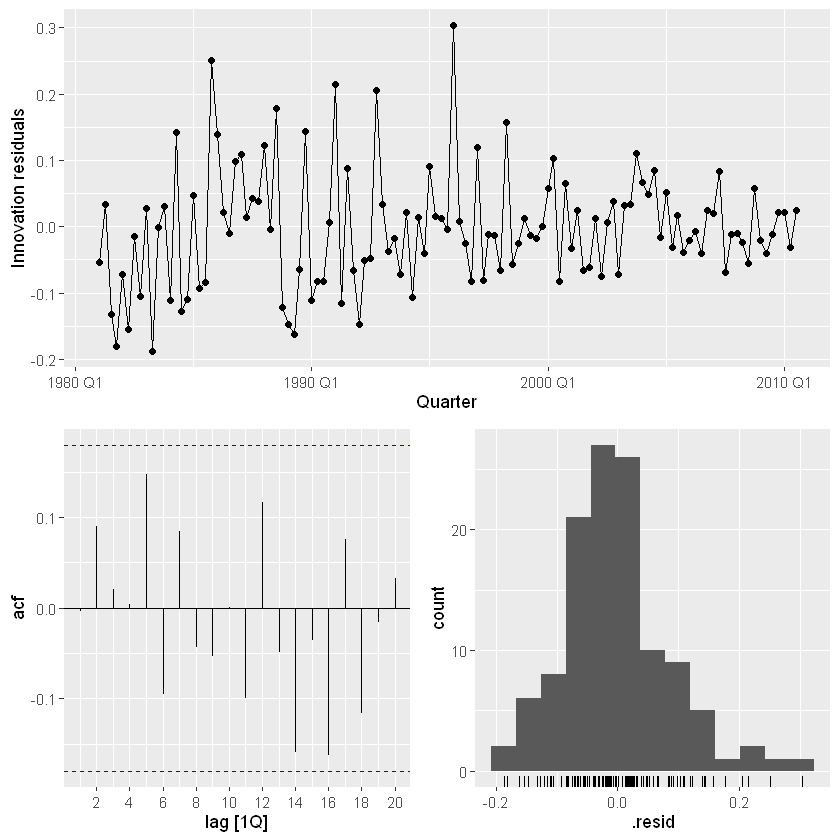

In [53]:
best_model <- fit_models |> select(Auto_ETS)

best_model |> gg_tsresiduals()

best_model |> augment() |> features(.innov, ljung_box, lag = 24)

In [54]:
# cross validation
cv_data <- aus_nz |>
  stretch_tsibble(.init = 40, .step = 1)

cv_fit <- cv_data |>
  model(
    Auto_ETS = ETS(Arrivals),
    Log_Additive_ETS = ETS(log(Arrivals) ~ error("A") + trend("A") + season("A")),
    SNaive = SNAIVE(Arrivals),
    STL_Log_ETS = decomposition_model(
      STL(log(Arrivals) ~ season(window = "periodic")),
      ETS(season_adjust ~ error("A") + trend("A") + season("N"))
    )
  ) |>
  forecast(h = 1)

cv_acc <- cv_fit |> accuracy(aus_nz)

cv_acc |> 
  select(.model, RMSE, MAE) |> 
  arrange(RMSE)

Warning message:
"The future dataset is incomplete, incomplete out-of-sample data will be treated as missing. 
1 observation is missing at 2012 Q4"


.model,RMSE,MAE
<chr>,<dbl>,<dbl>
Auto_ETS,13151.44,10337.55
Log_Additive_ETS,13280.66,10534.05
STL_Log_ETS,18620.41,14668.57
SNaive,19010.43,14654.60
